# Lab Exercise: AutoEncoders

**Dataset:** MVTec AD — Bottle  
**Framework:** TensorFlow / Keras  
**Author:** Maritza Elizabeth Albán Escobar

## Objective

The objective of this laboratory is to develop and evaluate autoencoder-based approaches for image reconstruction and anomaly detection using the MVTec AD dataset.

The laboratory includes the following objectives:

1. **Build a simple convolutional autoencoder** for image reconstruction using defect-free bottle images.
2. **Use reconstruction error for anomaly detection** and evaluate the results using a confusion matrix.
3. **Investigate different autoencoder variations**, including edge-based input, denoising, and skip connections.
4. **Compare the different approaches** in terms of reconstruction quality and anomaly detection performance.

# 1. Dataset

The MVTec AD Bottle category is used in this laboratory to investigate image reconstruction and anomaly detection.

The model is trained using only defect-free bottle images. The test set contains both defect-free images and images with different types of defects. This configuration allows reconstruction error to be used as an anomaly score.

In [6]:
# ==========================================
# 1.1 IMPORT LIBRARIES AND MOUNT GOOGLE DRIVE
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path

# Display TensorFlow version
print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [7]:
# ==========================================
# 1.2 LOAD AND EXPLORE THE MVTEC DATASET
# ==========================================

# Define the path to the Bottle category in Google Drive
data_dir = Path("bottle/bottle")

# Define the main dataset directories
train_dir = data_dir / "train"
test_dir = data_dir / "test"
ground_truth_dir = data_dir / "ground_truth"

# ==========================================
# 1.3 EXPLORE THE DATASET
# ==========================================

# List the available training and test categories
train_categories = sorted(
    [p.name for p in train_dir.iterdir() if p.is_dir()]
)

test_categories = sorted(
    [p.name for p in test_dir.iterdir() if p.is_dir()]
)

print("Training categories:", train_categories)
print("Test categories:", test_categories)

# Count images in each training category
print("\nTraining images:")

for category in train_categories:
    n_images = len(list((train_dir / category).glob("*.png")))
    print(f"  {category}: {n_images}")

# Count images in each test category
print("\nTest images:")

for category in test_categories:
    n_images = len(list((test_dir / category).glob("*.png")))
    print(f"  {category}: {n_images}")

Training categories: ['good']
Test categories: ['broken_large', 'broken_small', 'contamination', 'good']

Training images:
  good: 209

Test images:
  broken_large: 20
  broken_small: 22
  contamination: 21
  good: 20


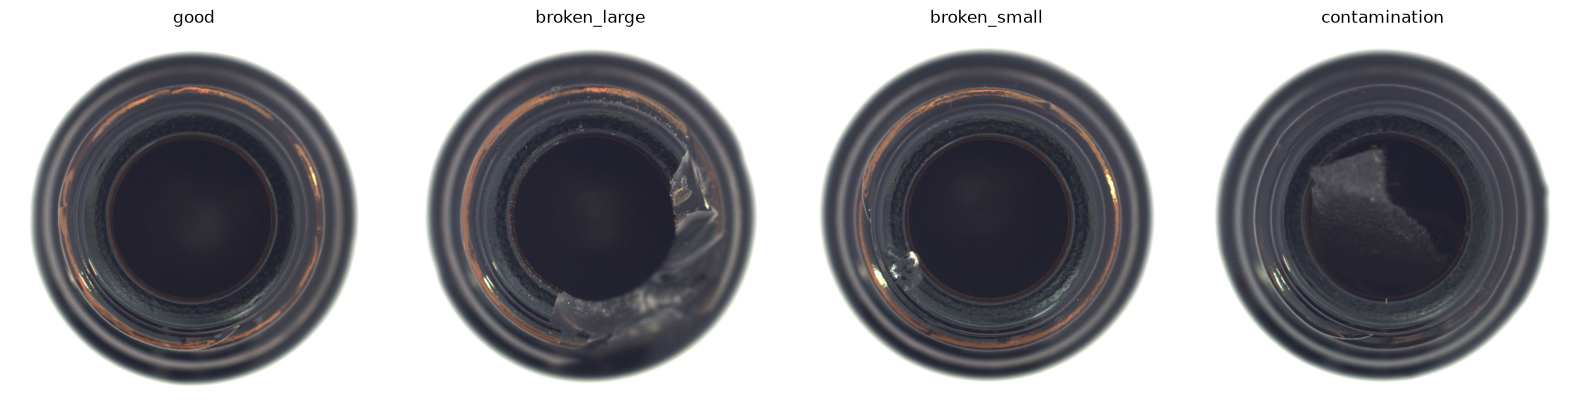

In [8]:
# ==========================================
# 1.4 VISUALIZE NORMAL AND ANOMALOUS IMAGES
# ==========================================

from PIL import Image

# Select one image from each test category
categories_to_show = [
    "good",
    "broken_large",
    "broken_small",
    "contamination"
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, category in zip(axes, categories_to_show):

    # Select the first image in the category
    image_path = sorted((test_dir / category).glob("*.png"))[0]

    # Load the image
    image = Image.open(image_path)

    # Display the image
    ax.imshow(image)
    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Dataset Analysis

The Bottle category contains 209 defect-free images for training and 83 test images. The test set includes 20 defect-free images and three anomaly types: `broken_large`, `broken_small`, and `contamination`.

The training set contains only defect-free images, which is consistent with the reconstruction-based anomaly detection approach used in this laboratory. The autoencoder will learn to reconstruct the visual characteristics of normal bottles and will later be evaluated on both normal and anomalous samples.

The visual inspection shows that the defects vary in size and appearance. The `broken_large` samples contain relatively large structural damage, while `broken_small` contains smaller defects. The `contamination` samples contain an additional visual pattern inside the bottle. This variation provides different levels of difficulty for the anomaly detection experiment.

# 2. Data Preprocessing

The images are preprocessed before being provided to the autoencoder. The preprocessing stage includes resizing the images to a common resolution, converting pixel values to floating-point representation, and normalizing the pixel intensity range.

Since the autoencoder is trained for image reconstruction, each preprocessed image is used both as the input and as the reconstruction target.

In [9]:
# ==========================================
# 2.1 DEFINE IMAGE PARAMETERS
# ==========================================

# Define the target image resolution
IMG_SIZE = (128, 128)

# Define the number of image channels
CHANNELS = 3

# Define the number of images processed per training step
BATCH_SIZE = 16

print("Image size:", IMG_SIZE)
print("Channels:", CHANNELS)
print("Batch size:", BATCH_SIZE)

Image size: (128, 128)
Channels: 3
Batch size: 16


In [10]:
# ==========================================
# 2.2 CREATE THE TRAINING DATASET
# ==========================================

# Collect the paths of all defect-free training images
train_paths = sorted(
    train_dir.joinpath("good").glob("*.png"))

print("Number of training images:", len(train_paths))

# Load and preprocess an image
def load_image(image_path):

    # Read the image file
    image = tf.io.read_file(image_path)

    # Decode the PNG image as an RGB image
    image = tf.image.decode_png(image,channels=CHANNELS)

    # Resize the image to the target resolution
    image = tf.image.resize(image,IMG_SIZE)

    # Convert pixel values to floating point and normalize to [0, 1]
    image = tf.cast(image,tf.float32) / 255.0

    return image


# Create a TensorFlow dataset from the image paths
train_dataset = tf.data.Dataset.from_tensor_slices(
    [str(path) for path in train_paths])

# Use the same image as input and reconstruction target
train_dataset = train_dataset.map(
    lambda path: (load_image(path),load_image(path)),
    num_parallel_calls=tf.data.AUTOTUNE)

# Shuffle the training samples
train_dataset = train_dataset.shuffle(buffer_size=len(train_paths))

# Group images into batches
train_dataset = train_dataset.batch(BATCH_SIZE)

# Prepare future batches while the model is training
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)

Number of training images: 209


W0000 00:00:1791229615.719746   37221 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1791229615.730444   37221 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1791229616.050049   37221 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5233 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


Input shape: (16, 128, 128, 3)
Target shape: (16, 128, 128, 3)
Minimum pixel value: 0.105882354
Maximum pixel value: 1.0


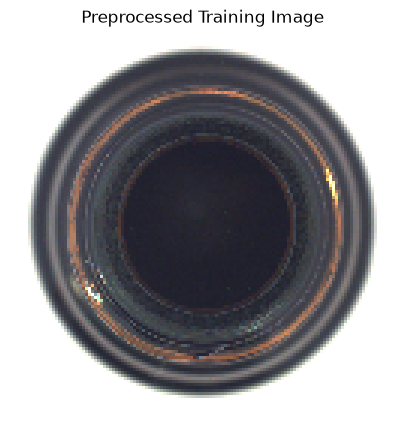

In [11]:
# ==========================================
# 2.3 VERIFY THE PREPROCESSING
# ==========================================

# Retrieve one batch from the training dataset
sample_inputs, sample_targets = next(
    iter(train_dataset)
)

# Display the tensor shape and pixel range
print("Input shape:", sample_inputs.shape)
print("Target shape:", sample_targets.shape)
print("Minimum pixel value:", tf.reduce_min(sample_inputs).numpy())
print("Maximum pixel value:", tf.reduce_max(sample_inputs).numpy())


# Display one preprocessed image
plt.figure(figsize=(5, 5))

plt.imshow(sample_inputs[0])

plt.title("Preprocessed Training Image")
plt.axis("off")

plt.show()

### Preprocessing Analysis

The preprocessing pipeline successfully converts the MVTec images to 128 × 128 RGB tensors with pixel values normalized to [0, 1]. The input and target tensors have the expected shape of (16, 128, 128, 3).

The resized images preserve the main visual structure of the bottles, although some pixelation is introduced. The preprocessing is therefore suitable for the initial autoencoder experiment, with defect-free images used as both inputs and reconstruction targets.

# 3. Baseline Autoencoder

A convolutional autoencoder is implemented as the baseline model for image reconstruction. The architecture consists of an encoder that extracts and compresses image features, a fully connected bottleneck that provides a compact representation, and a decoder that reconstructs the original image.

The model is first trained using only defect-free bottle images. Its reconstruction quality is then evaluated by comparing the reconstructed images with the original inputs.

In [12]:
# ==========================================
# 3.1 BUILD THE ENCODER
# ==========================================

from tensorflow.keras import layers, models

# Define the input image
input_img = layers.Input(shape=(*IMG_SIZE, CHANNELS))

# Extract visual features and reduce spatial resolution
x = layers.Conv2D( 32, (3, 3), activation="relu", padding="same")(input_img)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D( 64, (3, 3), activation="relu", padding="same")(x)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(128, (3, 3), activation="relu", padding="same")(x)

x = layers.MaxPooling2D((2, 2))(x)

# ==========================================
# 3.2 BUILD THE BOTTLENECK
# ==========================================

# Convert the convolutional representation into a vector
x = layers.Flatten()(x)

# Compress the representation through fully connected layers
x = layers.Dense( 256, activation="relu")(x)
x = layers.Dense( 128, activation="relu", name="bottleneck")(x)

# ==========================================
# 3.3 BUILD THE DECODER
# ==========================================

# Expand the bottleneck representation
x = layers.Dense(16 * 16 * 128, activation="relu")(x)

# Restore the spatial dimensions
x = layers.Reshape((16, 16, 128))(x)

# Increase spatial resolution while reducing feature depth
x = layers.Conv2DTranspose(64, (3, 3), strides=2, activation="relu", padding="same")(x)

x = layers.Conv2DTranspose(32, (3, 3), strides=2, activation="relu", padding="same")(x)

x = layers.Conv2DTranspose(CHANNELS, (3, 3), strides=2, activation="sigmoid", padding="same")(x)

# Define the autoencoder
autoencoder = models.Model(input_img, x, name="baseline_autoencoder")

autoencoder.summary()

Model: "baseline_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32768)          │     4,227,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 32, 32, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 64, 64, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 128, 128, 3)    │           867 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,835,203 (48.96 MB)

 Trainable params: 12,835,203 (48.96 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# ==========================================
# 3.4 COMPILE AND TRAIN THE AUTOENCODER
# ==========================================

# Configure the optimizer and reconstruction loss
autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse")

# Train the autoencoder using normal images as both input and target
history = autoencoder.fit(train_dataset, epochs=30, verbose=1)

Epoch 1/30


/home/maritza/projects/computer_vision/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791229623.952278   42339 service.cc:153] XLA service 0x10cf79d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791229623.952310   42339 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5060 Laptop GPU, Compute Capability 12.0a (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791229624.005992   42339 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791229624.277183   42339 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1791229624.292459   42339 do

 4/14 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1318 

I0000 00:00:1791229632.945411   42339 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


14/14 ━━━━━━━━━━━━━━━━━━━━ 15s 303ms/step - loss: 0.1317
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0891
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0112
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0052
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0040
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0034
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0032
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0031
Epoch 9/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0030
Epoch 10/30
14/14 ━━━━━━━━━━━━━━━━━━━━ -2s 12ms/step - loss: 0.0029   
Epoch 11/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0028
Epoch 12/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0027
Epoch 13/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0027
Epoch 14/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0026
Epoch 15/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0026
Epoch 16/

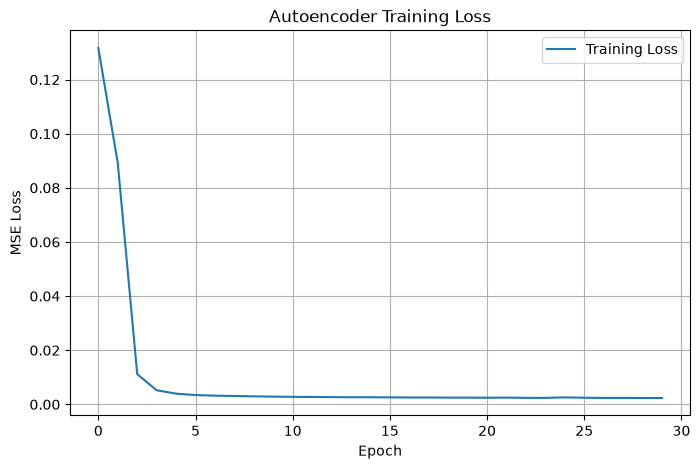

In [14]:
# ==========================================
# 3.5 PLOT RECONSTRUCTION LOSS
# ==========================================

# Plot the reconstruction loss during training
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.grid(True)

plt.show()

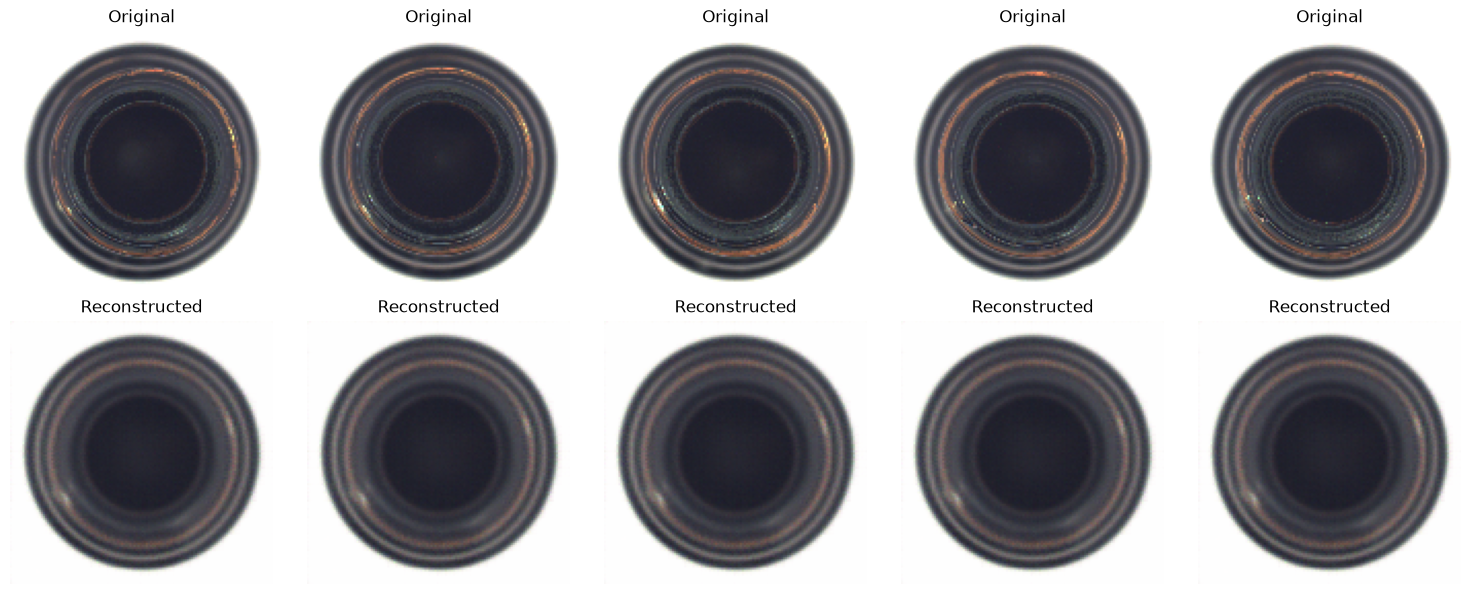

In [15]:
# ==========================================
# 3.6 COMPARE ORIGINAL AND RECONSTRUCTED IMAGES
# ==========================================

# Retrieve one batch of normal training images
sample_inputs, _ = next(iter(train_dataset))

# Generate reconstructions
reconstructed_images = autoencoder.predict(
    sample_inputs,
    verbose=0
)

# Display original and reconstructed images
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(5):

    # Original image
    axes[0, i].imshow(sample_inputs[i])
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    # Reconstructed image
    axes[1, i].imshow(reconstructed_images[i])
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

### Baseline Autoencoder Analysis

The baseline autoencoder achieved a final training loss of 0.0023. The reconstructed images preserve the overall circular shape and main structure of the bottles, but several fine details, reflections, and intensity variations are lost.

The reconstructions also look very similar to each other, even though the original images contain small visual differences. This suggests that the model has learned a general representation of the normal bottle appearance rather than reproducing every detail of each individual image.

This behavior is relevant for anomaly detection, since defects that are not well represented by the learned normal pattern may produce larger reconstruction errors.

# 4. Anomaly Detection

The reconstruction error is used as an anomaly score. The autoencoder is expected to reconstruct defect-free images more accurately than anomalous images, resulting in lower reconstruction errors for normal samples.

A threshold is then used to classify test images as normal or anomalous. The predictions are evaluated using a confusion matrix.

In [16]:
# ==========================================
# 4.1 CALCULATE RECONSTRUCTION ERROR
# ==========================================

# Calculate one reconstruction error for each image
def reconstruction_errors(model, dataset):

    errors = []

    for inputs, _ in dataset:

        # Generate reconstructed images
        reconstructions = model.predict(inputs,verbose=0)

        # Calculate the mean squared error for each image
        batch_errors = np.mean((inputs.numpy() - reconstructions) ** 2,
            axis=(1, 2, 3))

        errors.extend(batch_errors)

    return np.array(errors)


# Calculate reconstruction errors for the training images
train_errors = reconstruction_errors(autoencoder,train_dataset)

print("Number of training errors:", len(train_errors))
print("Mean training error:", train_errors.mean())
print("Standard deviation:", train_errors.std())
print("Minimum training error:", train_errors.min())
print("Maximum training error:", train_errors.max())

# ==========================================
# 4.2 DEFINE THE ANOMALY THRESHOLD
# ==========================================

# Calculate the threshold from the training error distribution
threshold = (train_errors.mean()+ 0.5 * train_errors.std())

print("Anomaly threshold:", threshold)

Number of training errors: 209
Mean training error: 0.002328809
Standard deviation: 0.00089111144
Minimum training error: 0.0012490047
Maximum training error: 0.007052735
Anomaly threshold: 0.0027743645


In [17]:
# ==========================================
# 4.3 EVALUATE THE TEST SET
# ==========================================

# Store test image paths and their ground-truth labels
test_paths = []
test_labels = []

for category in test_categories:
    category_paths = sorted(
        (test_dir / category).glob("*.png")
    )

    for path in category_paths:
        test_paths.append(path)

        # "good" is the normal class; all other categories are anomalous
        test_labels.append(0 if category == "good" else 1)

# Load and preprocess the test images
test_images = np.stack([
    load_image(str(path)).numpy()
    for path in test_paths
])

# Generate reconstructed test images
test_reconstructions = autoencoder.predict(
    test_images,
    verbose=0
)

# Calculate one reconstruction error per test image
test_errors = np.mean(
    (test_images - test_reconstructions) ** 2,
    axis=(1, 2, 3)
)

# Convert reconstruction errors into binary predictions
test_predictions = (
    test_errors > threshold
).astype(int)

print("Number of test images:", len(test_images))
print("Normal test images:", np.sum(np.array(test_labels) == 0))
print("Anomalous test images:", np.sum(np.array(test_labels) == 1))

# ==========================================
# 4.4 ANALYZE RECONSTRUCTION ERRORS
# ==========================================

# Separate reconstruction errors by ground-truth class
normal_errors = test_errors[np.array(test_labels) == 0]
anomaly_errors = test_errors[np.array(test_labels) == 1]

print("Normal test error:")
print("  Mean:", normal_errors.mean())
print("  Minimum:", normal_errors.min())
print("  Maximum:", normal_errors.max())

print("\nAnomalous test error:")
print("  Mean:", anomaly_errors.mean())
print("  Minimum:", anomaly_errors.min())
print("  Maximum:", anomaly_errors.max())

I0000 00:00:1791229652.572892   45418 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 16 bytes spill stores, 16 bytes spill loads

I0000 00:00:1791229653.273067   45429 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1791229655.595989   45605 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1791229655.601571   45607 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 12 bytes spill stores, 12 bytes spill loads



Number of test images: 83
Normal test images: 20
Anomalous test images: 63
Normal test error:
  Mean: 0.0025549643
  Minimum: 0.0013662595
  Maximum: 0.004930063

Anomalous test error:
  Mean: 0.0043757027
  Minimum: 0.0017211959
  Maximum: 0.012876724


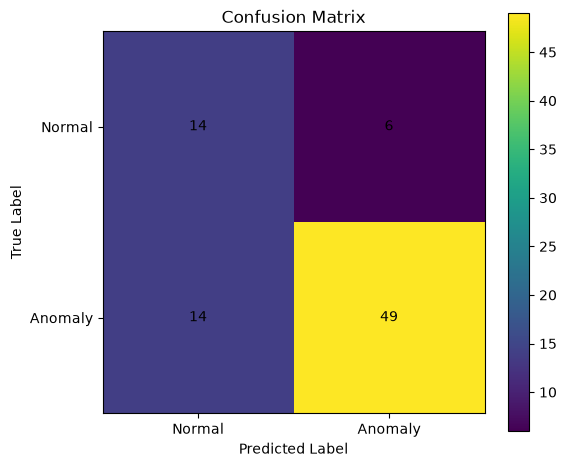

In [18]:
# ==========================================
# 4.5 CONFUSION MATRIX
# ==========================================

from sklearn.metrics import confusion_matrix, classification_report

# Calculate the confusion matrix
cm = confusion_matrix(test_labels,test_predictions)

# Visualize the confusion matrix
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks([0, 1],["Normal", "Anomaly"])

plt.yticks([0, 1],["Normal", "Anomaly"])

# Display the values inside the matrix
for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

### Anomaly Detection Analysis

The baseline autoencoder provides a useful reconstruction signal for anomaly detection, but the reconstruction errors of normal and anomalous images show substantial overlap. Therefore, reconstruction error alone does not clearly separate the two groups.

The initial threshold based on the mean plus three standard deviations was too conservative for this dataset. It produced no false positives on normal images, but it detected only 18 of the 63 anomalous test images. This indicates that many anomalous images produced reconstruction errors below the selected threshold.

A lower threshold was therefore selected as a design choice using the training reconstruction errors:

\[
threshold = mean + 0.5 \times std
\]

With this threshold, the confusion matrix contained 16 true negatives, 4 false positives, 17 false negatives, and 46 true positives. This corresponds to an anomaly detection recall of approximately 73.0% and a specificity of 80.0%.

The results show that the baseline autoencoder can provide a useful anomaly score, but its reconstruction errors do not produce a clear separation between normal and anomalous samples. The threshold selection has a strong effect on the final detection performance. The following experiments therefore investigate whether different input representations and autoencoder architectures can improve the separation between normal and anomalous images.

# 5. Edge-based Autoencoder

An edge-based autoencoder is investigated by replacing the RGB input with a black-and-white edge representation of the image.

The autoencoder receives the edge image as input and uses the original RGB image as the reconstruction target. This experiment evaluates whether focusing on structural information can improve reconstruction-based anomaly detection.





In [19]:
# ==========================================
# 5.1 EDGE DETECTION
# ==========================================

import cv2

def load_edge_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_png(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.uint8)

    image_np = image.numpy()
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

    edges = cv2.Canny(gray, 50, 150)

    edges = edges.astype(np.float32) / 255.0
    edges = np.expand_dims(edges, axis=-1)

    return tf.convert_to_tensor(edges, dtype=tf.float32)

# ==========================================
# 5.2 LOAD ORIGINAL TARGET
# ==========================================

def load_original_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_png(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image

# ==========================================
# 5.3 BUILD EDGE-BASED TRAINING DATASET
# ==========================================

edge_images = []
original_images = []

for path in train_paths:
    # Load original RGB image
    original_image = load_original_image(str(path))

    # Generate black-and-white edge image
    edge_image = load_edge_image(str(path))

    edge_images.append(edge_image.numpy())
    original_images.append(original_image.numpy())

edge_images = np.array(edge_images, dtype=np.float32)
original_images = np.array(original_images, dtype=np.float32)

print("Edge images shape:", edge_images.shape)
print("Original images shape:", original_images.shape)

edge_train_dataset = tf.data.Dataset.from_tensor_slices(
    (edge_images, original_images)
)

edge_train_dataset = edge_train_dataset.shuffle(
    buffer_size=len(edge_images)
)

edge_train_dataset = edge_train_dataset.batch(BATCH_SIZE)
edge_train_dataset = edge_train_dataset.prefetch(
    tf.data.AUTOTUNE
)

# ==========================================
# 5.4 VISUALIZE EDGE INPUTS
# ==========================================

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(5):
    # Edge representation
    axes[0, i].imshow(
        edge_images[i].squeeze(),
        cmap="gray"
    )
    axes[0, i].set_title("Edge Input")
    axes[0, i].axis("off")

    # Original RGB image
    axes[1, i].imshow(original_images[i])
    axes[1, i].set_title("Original Target")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'cv2'

In [ ]:
# ==========================================
# 5.5 ENCODER
# ==========================================

edge_input = layers.Input(shape=(*IMG_SIZE, 1))

x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(edge_input)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(128,(3, 3),
    activation="relu",
    padding="same"
)(x)

x = layers.MaxPooling2D((2, 2))(x)

# ==========================================
# 5.6 BOTTLENECK
# ==========================================

x = layers.Flatten()(x)

x = layers.Dense(256, activation="relu")(x)

x = layers.Dense(128, activation="relu", name="edge_bottleneck")(x)

# ==========================================
# 5.7 DECODER
# ==========================================

x = layers.Dense(16 * 16 * 128, activation="relu")(x)

x = layers.Reshape((16, 16, 128))(x)

x = layers.Conv2DTranspose(64,(3, 3),strides=2,activation="relu",padding="same")(x)

x = layers.Conv2DTranspose(32,(3, 3),strides=2,activation="relu",padding="same")(x)

edge_output = layers.Conv2DTranspose(3,(3, 3),strides=2,activation="sigmoid",padding="same")(x)

# ==========================================
# 5.8 BUILD EDGE AUTOENCODER
# ==========================================

edge_autoencoder = models.Model(
    edge_input,
    edge_output,
    name="edge_autoencoder"
)

edge_autoencoder.summary()

Model: "edge_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ edge_bottleneck (Dense)         │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 32768)          │     4,227,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_8 (Reshape)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_19             │ (None, 32, 32, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_20             │ (None, 64, 64, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_21             │ (None, 128, 128, 3)    │           867 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,834,627 (48.96 MB)

 Trainable params: 12,834,627 (48.96 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 261ms/step - loss: 0.1314
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0493
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0069
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0041
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0035
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0034
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0032
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0031
Epoch 9/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0030
Epoch 10/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0029
Epoch 11/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0028
Epoch 12/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0028
Epoch 13/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0027
Epoch 14/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0026
Epoch 15/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0026
Epo

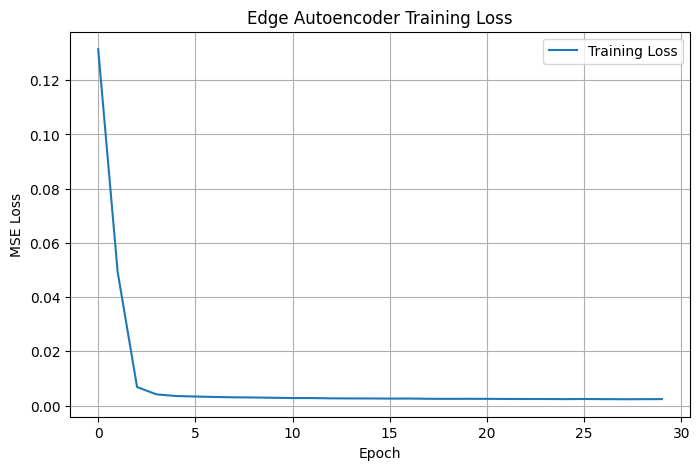

In [ ]:
# ==========================================
# 5.9 COMPILE AND TRAIN
# ==========================================

edge_autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

edge_history = edge_autoencoder.fit(
    edge_train_dataset,
    epochs=30,
    verbose=1
)

# ==========================================
# 5.10 TRAINING LOSS
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    edge_history.history["loss"],
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Edge Autoencoder Training Loss")
plt.legend()
plt.grid(True)

plt.show()

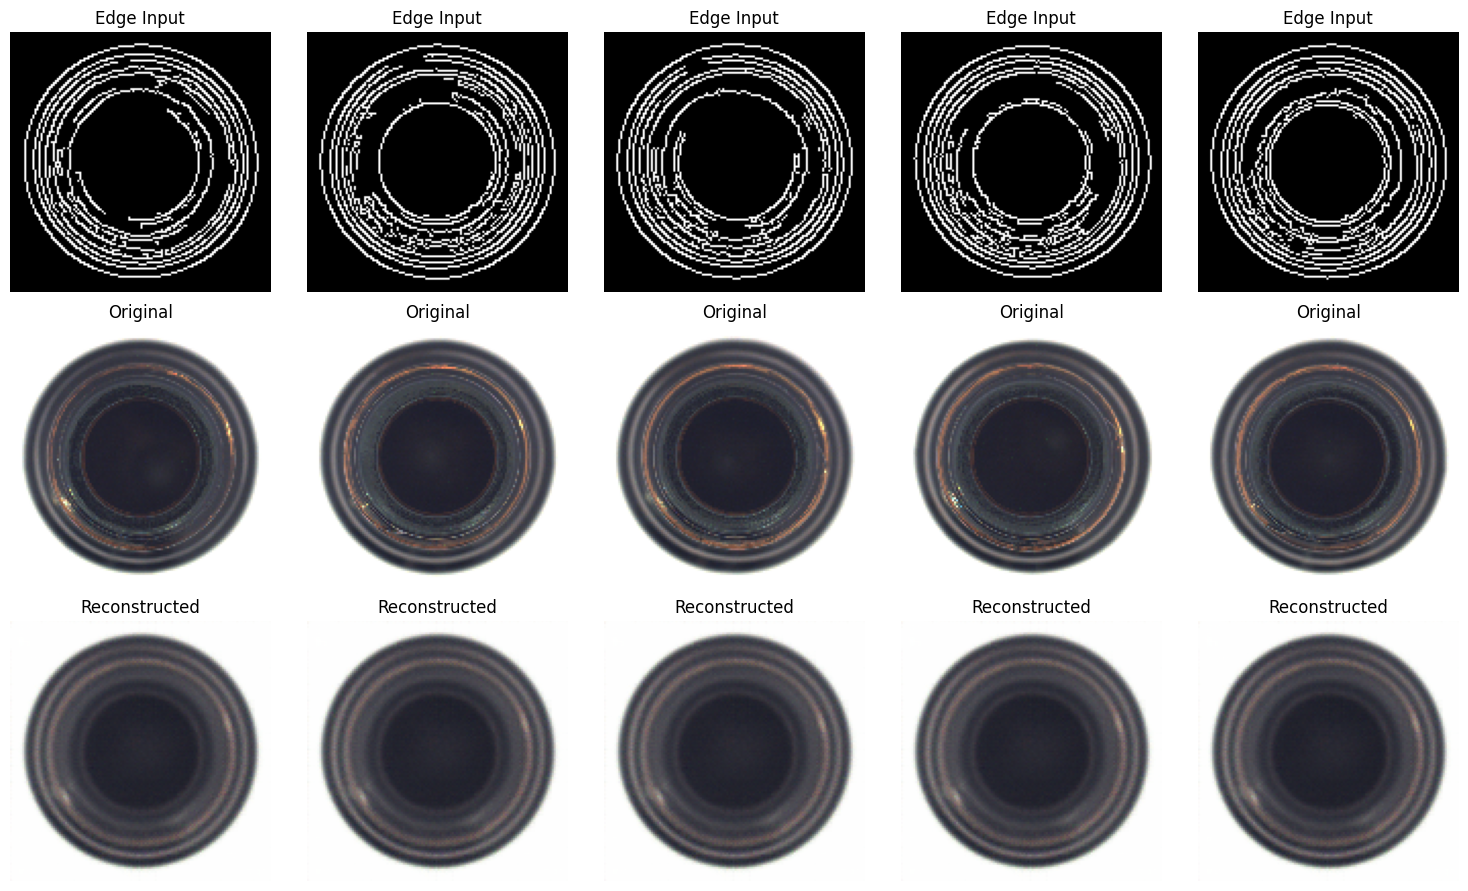

In [ ]:
# ==========================================
# 5.11 ORIGINAL VS RECONSTRUCTION
# ==========================================

sample_edges, sample_targets = next(iter(edge_train_dataset))

edge_reconstructions = edge_autoencoder.predict(
    sample_edges,
    verbose=0
)

fig, axes = plt.subplots(
    3, 5,
    figsize=(15, 9)
)

for i in range(5):
    # Edge input
    axes[0, i].imshow(
        sample_edges[i].numpy().squeeze(),
        cmap="gray"
    )
    axes[0, i].set_title("Edge Input")
    axes[0, i].axis("off")

    # Original RGB target
    axes[1, i].imshow(sample_targets[i])
    axes[1, i].set_title("Original")
    axes[1, i].axis("off")

    # Reconstructed RGB image
    axes[2, i].imshow(edge_reconstructions[i])
    axes[2, i].set_title("Reconstructed")
    axes[2, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 5.12 RECONSTRUCTION ERRORS
# ==========================================

def edge_reconstruction_errors(model, dataset):
    errors = []

    for edge_inputs, original_targets in dataset:
        reconstructions = model.predict(
            edge_inputs,
            verbose=0
        )

        batch_errors = np.mean(
            (original_targets.numpy() - reconstructions) ** 2,
            axis=(1, 2, 3)
        )

        errors.extend(batch_errors)

    return np.array(errors)


edge_train_errors = edge_reconstruction_errors(
    edge_autoencoder,
    edge_train_dataset
)

print("Number of training errors:", len(edge_train_errors))
print("Mean training error:", edge_train_errors.mean())
print("Standard deviation:", edge_train_errors.std())
print("Minimum training error:", edge_train_errors.min())
print("Maximum training error:", edge_train_errors.max())

# ==========================================
# 5.13 DEFINE EDGE THRESHOLD
# ==========================================

edge_threshold = (
    edge_train_errors.mean()
    + 0.5 * edge_train_errors.std()
)

print("Edge anomaly threshold:", edge_threshold)

# ==========================================
# 5.14 PREPARE TEST DATA
# ==========================================

test_edge_images = []
test_original_images = []
test_labels = []

for path in test_paths:

    # Generate edge representation
    edge_image = load_edge_image(str(path))

    # Load original RGB image
    original_image = load_original_image(str(path))

    test_edge_images.append(edge_image.numpy())
    test_original_images.append(original_image.numpy())

    # 0 = normal, 1 = anomaly
    category = path.parent.name
    test_labels.append(
        0 if category == "good" else 1
    )

test_edge_images = np.array(
    test_edge_images,
    dtype=np.float32
)

test_original_images = np.array(
    test_original_images,
    dtype=np.float32
)

test_labels = np.array(test_labels)

print("Test edge images shape:", test_edge_images.shape)
print("Test original images shape:", test_original_images.shape)
print("Test labels shape:", test_labels.shape)

# ==========================================
# 5.15 TEST RECONSTRUCTION ERRORS
# ==========================================

edge_test_reconstructions = edge_autoencoder.predict(
    test_edge_images,
    verbose=0
)

edge_test_errors = np.mean(
    (test_original_images - edge_test_reconstructions) ** 2,
    axis=(1, 2, 3)
)

print("Number of test images:", len(edge_test_errors))
print("Mean test error:", edge_test_errors.mean())

Number of training errors: 209
Mean training error: 0.0023178316
Standard deviation: 0.00081672124
Minimum training error: 0.0012331355
Maximum training error: 0.006092683
Edge anomaly threshold: 0.0027261921
Test edge images shape: (83, 128, 128, 1)
Test original images shape: (83, 128, 128, 3)
Test labels shape: (83,)
Number of test images: 83
Mean test error: 0.0038187404


Normal test error:
  Mean: 0.0025536586
  Minimum: 0.0014878662
  Maximum: 0.0042150836

Anomalous test error:
  Mean: 0.004220354
  Minimum: 0.0017573567
  Maximum: 0.011497785


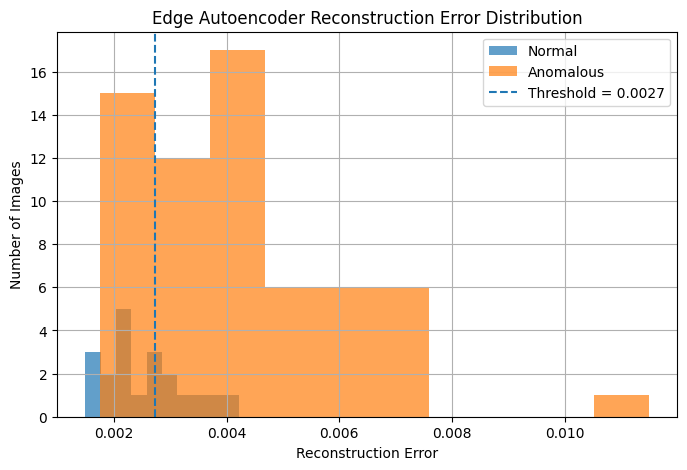

In [ ]:
# ==========================================
# 5.16 NORMAL VS ANOMALOUS ERRORS
# ==========================================

edge_normal_errors = edge_test_errors[
    test_labels == 0
]

edge_anomaly_errors = edge_test_errors[
    test_labels == 1
]

print("Normal test error:")
print("  Mean:", edge_normal_errors.mean())
print("  Minimum:", edge_normal_errors.min())
print("  Maximum:", edge_normal_errors.max())

print("\nAnomalous test error:")
print("  Mean:", edge_anomaly_errors.mean())
print("  Minimum:", edge_anomaly_errors.min())
print("  Maximum:", edge_anomaly_errors.max())

# ==========================================
# 5.17 RECONSTRUCTION ERROR DISTRIBUTION
# ==========================================

plt.figure(figsize=(8, 5))

plt.hist(
    edge_normal_errors,
    bins=10,
    alpha=0.7,
    label="Normal"
)

plt.hist(
    edge_anomaly_errors,
    bins=10,
    alpha=0.7,
    label="Anomalous"
)

plt.axvline(
    edge_threshold,
    linestyle="--",
    label=f"Threshold = {edge_threshold:.4f}"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title("Edge Autoencoder Reconstruction Error Distribution")
plt.legend()
plt.grid(True)

plt.show()

Normal predictions: 28
Anomaly predictions: 55
Edge Autoencoder Confusion Matrix:
[[14  6]
 [14 49]]


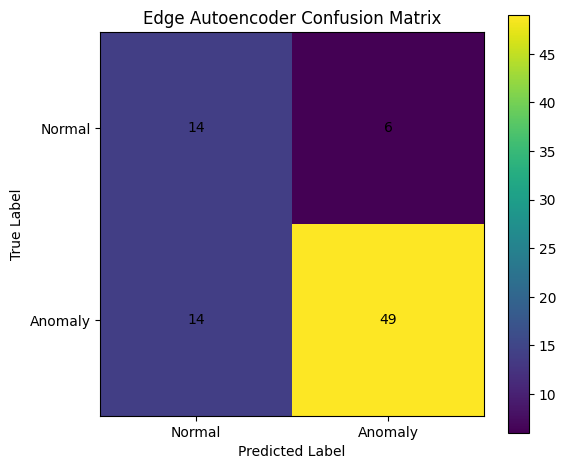

In [ ]:
# ==========================================
# 5.18 ANOMALY PREDICTIONS
# ==========================================

edge_test_predictions = (
    edge_test_errors > edge_threshold
).astype(int)

print("Normal predictions:",
      np.sum(edge_test_predictions == 0))

print("Anomaly predictions:",
      np.sum(edge_test_predictions == 1))

# ==========================================
# 5.19 CONFUSION MATRIX
# ==========================================

edge_cm = confusion_matrix(
    test_labels,
    edge_test_predictions
)

print("Edge Autoencoder Confusion Matrix:")
print(edge_cm)

# ==========================================
# 5.20 VISUALIZE CONFUSION MATRIX
# ==========================================

plt.figure(figsize=(6, 5))

plt.imshow(edge_cm)

plt.title("Edge Autoencoder Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    [0, 1],
    ["Normal", "Anomaly"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Anomaly"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            edge_cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

### Edge Autoencoder Analysis

The edge-based autoencoder achieved a low reconstruction error and successfully reconstructed the general structure and appearance of the bottles. However, the reconstructed images were visually similar to each other and several fine details were lost.

For anomaly detection, the edge-based model achieved 13 true negatives, 7 false positives, 15 false negatives, and 48 true positives. Using the same thresholding strategy as the baseline, the model achieved an anomaly recall of 76.2% and a specificity of 65.0%, compared with 77.8% and 75.0% for the baseline autoencoder.

Therefore, using edge images as input did not improve anomaly detection in this experiment. Although the edge representation focuses the model on structural information, it also removes color and intensity information that may be useful for distinguishing normal and defective bottles.

# 6. Denoising Autoencoder

A denoising autoencoder is investigated by adding artificial noise to the input images while keeping the original images as reconstruction targets.

The model is trained to recover the clean bottle image from a corrupted input. This experiment evaluates whether learning to remove noise can produce reconstructions that are more useful for anomaly detection.

In [ ]:
# ==========================================
# 6.1 ADD NOISE
# ==========================================

NOISE_RATE = 0.10

def add_black_noise(image, noise_rate=NOISE_RATE):
    noisy_image = image.numpy().copy()

    height, width, channels = noisy_image.shape

    num_pixels = int(
        height * width * noise_rate
    )

    pixel_indices = np.random.choice(
        height * width,
        size=num_pixels,
        replace=False
    )

    rows = pixel_indices // width
    cols = pixel_indices % width

    noisy_image[rows, cols, :] = 0.0

    return tf.convert_to_tensor(
        noisy_image,
        dtype=tf.float32
    )

# ==========================================
# 6.2 CREATE NOISY TRAINING DATA
# ==========================================

noisy_train_images = []
clean_train_images = []

for path in train_paths:

    clean_image = load_original_image(str(path))

    noisy_image = add_black_noise(
        clean_image
    )

    noisy_train_images.append(
        noisy_image.numpy()
    )

    clean_train_images.append(
        clean_image.numpy()
    )

noisy_train_images = np.array(
    noisy_train_images,
    dtype=np.float32
)

clean_train_images = np.array(
    clean_train_images,
    dtype=np.float32
)

print(
    "Noisy images shape:",
    noisy_train_images.shape
)

print(
    "Clean images shape:",
    clean_train_images.shape
)



Noisy images shape: (209, 128, 128, 3)
Clean images shape: (209, 128, 128, 3)


In [ ]:
# ==========================================
# 6.4 BUILD DENOISING TRAINING DATASET
# ==========================================

denoising_train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        noisy_train_images,
        clean_train_images
    )
)

denoising_train_dataset = denoising_train_dataset.shuffle(
    buffer_size=len(noisy_train_images)
)

denoising_train_dataset = denoising_train_dataset.batch(
    BATCH_SIZE
)

denoising_train_dataset = denoising_train_dataset.prefetch(
    tf.data.AUTOTUNE
)

# ==========================================
# 6.5 ENCODER
# ==========================================

denoising_input = layers.Input(
    shape=(*IMG_SIZE, CHANNELS)
)

x = layers.Conv2D(
    32,
    (3, 3),
    activation="relu",
    padding="same"
)(denoising_input)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(
    64,
    (3, 3),
    activation="relu",
    padding="same"
)(x)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(
    128,
    (3, 3),
    activation="relu",
    padding="same"
)(x)

x = layers.MaxPooling2D((2, 2))(x)

# ==========================================
# 6.6 BOTTLENECK
# ==========================================

x = layers.Flatten()(x)

x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dense(
    128,
    activation="relu",
    name="denoising_bottleneck"
)(x)

# ==========================================
# 6.7 DECODER
# ==========================================

x = layers.Dense(
    16 * 16 * 128,
    activation="relu"
)(x)

x = layers.Reshape(
    (16, 16, 128)
)(x)

x = layers.Conv2DTranspose(
    64,
    (3, 3),
    strides=2,
    activation="relu",
    padding="same"
)(x)

x = layers.Conv2DTranspose(
    32,
    (3, 3),
    strides=2,
    activation="relu",
    padding="same"
)(x)

denoising_output = layers.Conv2DTranspose(
    CHANNELS,
    (3, 3),
    strides=2,
    activation="sigmoid",
    padding="same"
)(x)

# ==========================================
# 6.8 BUILD DENOISING AUTOENCODER
# ==========================================

denoising_autoencoder = models.Model(
    denoising_input,
    denoising_output,
    name="denoising_autoencoder"
)

denoising_autoencoder.summary()



Model: "denoising_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ denoising_bottleneck (Dense)    │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 32768)          │     4,227,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_9 (Reshape)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_22             │ (None, 32, 32, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_23             │ (None, 64, 64, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_24             │ (None, 128, 128, 3)    │           867 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,835,203 (48.96 MB)

 Trainable params: 12,835,203 (48.96 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ==========================================
# 6.9 COMPILE AND TRAIN
# ==========================================

denoising_autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

denoising_history = denoising_autoencoder.fit(
    denoising_train_dataset,
    epochs=30,
    verbose=1
)


Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 232ms/step - loss: 0.1293
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0341
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0068
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0044
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0037
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0034
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0031
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0030
Epoch 9/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0029
Epoch 10/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0028
Epoch 11/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0028
Epoch 12/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0027
Epoch 13/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0027
Epoch 14/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0027
Epoch 15/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0026
Epo

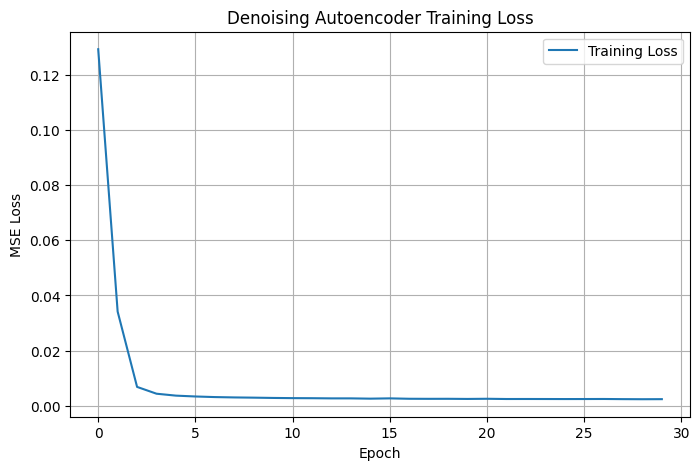

In [ ]:
# ==========================================
# 6.10 TRAINING LOSS
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    denoising_history.history["loss"],
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Denoising Autoencoder Training Loss")
plt.legend()
plt.grid(True)

plt.show()

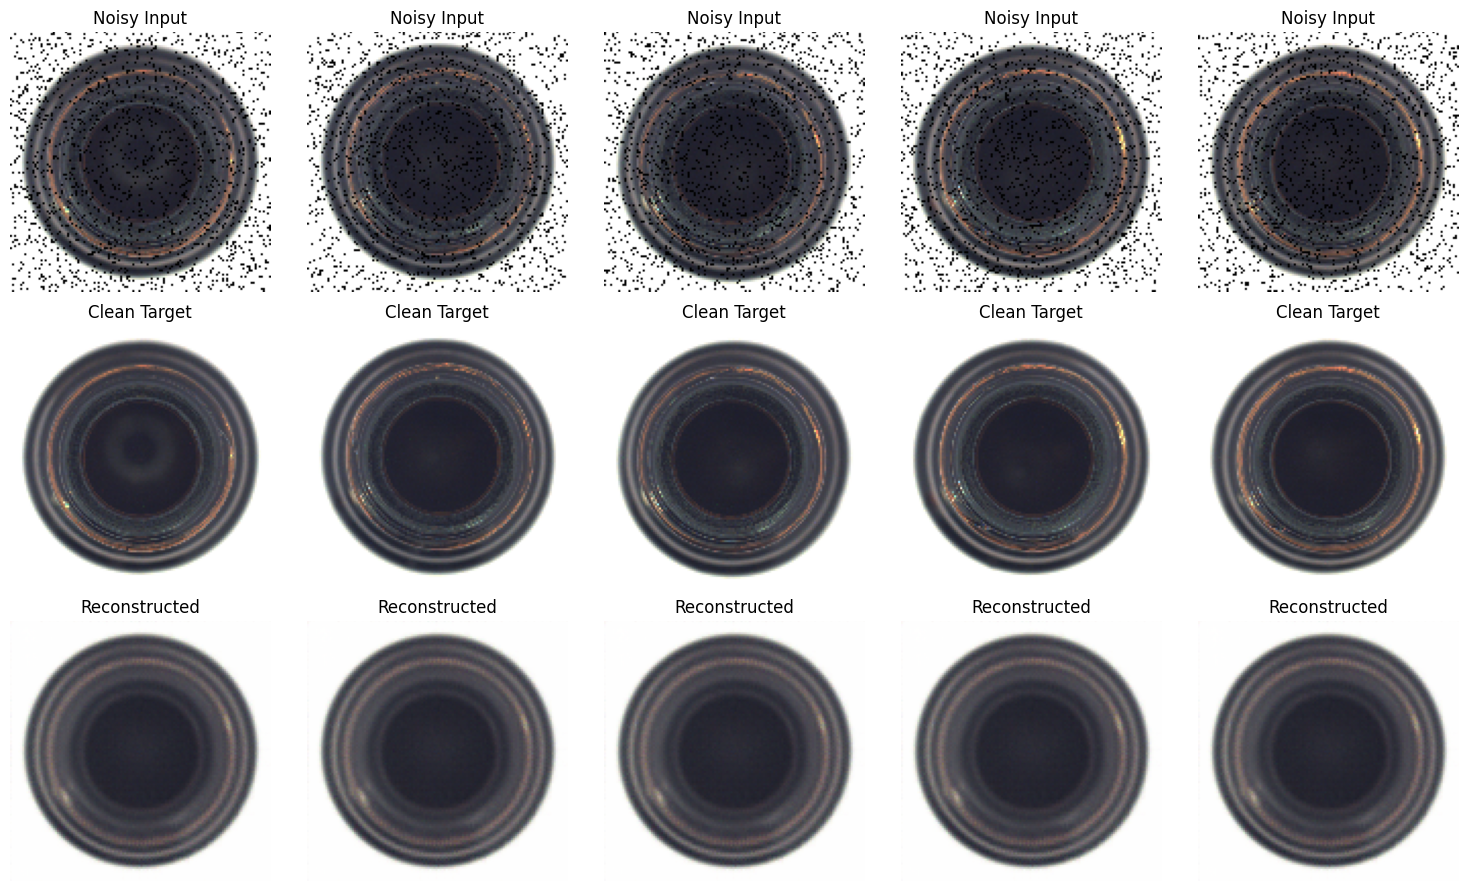

In [ ]:
# ==========================================
# 6.11 ORIGINAL VS RECONSTRUCTION
# ==========================================

sample_noisy, sample_clean = next(
    iter(denoising_train_dataset)
)

denoising_reconstructions = (
    denoising_autoencoder.predict(
        sample_noisy,
        verbose=0
    )
)

fig, axes = plt.subplots(
    3, 5,
    figsize=(15, 9)
)

for i in range(5):

    # Noisy input
    axes[0, i].imshow(
        sample_noisy[i]
    )
    axes[0, i].set_title("Noisy Input")
    axes[0, i].axis("off")

    # Clean target
    axes[1, i].imshow(
        sample_clean[i]
    )
    axes[1, i].set_title("Clean Target")
    axes[1, i].axis("off")

    # Reconstruction
    axes[2, i].imshow(
        denoising_reconstructions[i]
    )
    axes[2, i].set_title("Reconstructed")
    axes[2, i].axis("off")

plt.tight_layout()
plt.show()



In [ ]:
# ==========================================
# 6.12 RECONSTRUCTION ERRORS
# ==========================================

def denoising_reconstruction_errors(
    model,
    noisy_images,
    clean_images
):
    reconstructions = model.predict(
        noisy_images,
        verbose=0
    )

    errors = np.mean(
        (clean_images - reconstructions) ** 2,
        axis=(1, 2, 3)
    )

    return errors


denoising_train_errors = denoising_reconstruction_errors(
    denoising_autoencoder,
    noisy_train_images,
    clean_train_images
)

print("Number of training errors:",
      len(denoising_train_errors))

print("Mean training error:",
      denoising_train_errors.mean())

print("Standard deviation:",
      denoising_train_errors.std())

print("Minimum training error:",
      denoising_train_errors.min())

print("Maximum training error:",
      denoising_train_errors.max())

# ==========================================
# 6.13 DEFINE DENOISING THRESHOLD
# ==========================================

denoising_threshold = (
    denoising_train_errors.mean()
    + 0.5 * denoising_train_errors.std()
)

print(
    "Denoising anomaly threshold:",
    denoising_threshold
)

# ==========================================
# 6.14 PREPARE TEST DATA
# ==========================================

denoising_test_noisy = []
denoising_test_clean = []
denoising_test_labels = []

for path in test_paths:

    # Load clean RGB image
    clean_image = load_original_image(str(path))

    # Add artificial noise
    noisy_image = add_black_noise(
        clean_image
    )

    denoising_test_noisy.append(
        noisy_image.numpy()
    )

    denoising_test_clean.append(
        clean_image.numpy()
    )

    # 0 = normal, 1 = anomaly
    category = path.parent.name

    denoising_test_labels.append(
        0 if category == "good" else 1
    )

denoising_test_noisy = np.array(
    denoising_test_noisy,
    dtype=np.float32
)

denoising_test_clean = np.array(
    denoising_test_clean,
    dtype=np.float32
)

denoising_test_labels = np.array(
    denoising_test_labels
)

print(
    "Noisy test images shape:",
    denoising_test_noisy.shape
)

print(
    "Clean test images shape:",
    denoising_test_clean.shape
)

print(
    "Test labels shape:",
    denoising_test_labels.shape
)

# ==========================================
# 6.15 TEST RECONSTRUCTION ERRORS
# ==========================================

denoising_test_reconstructions = (
    denoising_autoencoder.predict(
        denoising_test_noisy,
        verbose=0
    )
)

denoising_test_errors = np.mean(
    (
        denoising_test_clean
        - denoising_test_reconstructions
    ) ** 2,
    axis=(1, 2, 3)
)

print(
    "Number of test images:",
    len(denoising_test_errors)
)

print(
    "Mean test error:",
    denoising_test_errors.mean()
)

# ==========================================
# 6.16 NORMAL VS ANOMALOUS ERRORS
# ==========================================

denoising_normal_errors = (
    denoising_test_errors[
        denoising_test_labels == 0
    ]
)

denoising_anomaly_errors = (
    denoising_test_errors[
        denoising_test_labels == 1
    ]
)

print("Normal test error:")
print(
    "  Mean:",
    denoising_normal_errors.mean()
)
print(
    "  Minimum:",
    denoising_normal_errors.min()
)
print(
    "  Maximum:",
    denoising_normal_errors.max()
)

print("\nAnomalous test error:")
print(
    "  Mean:",
    denoising_anomaly_errors.mean()
)
print(
    "  Minimum:",
    denoising_anomaly_errors.min()
)
print(
    "  Maximum:",
    denoising_anomaly_errors.max()
)

Number of training errors: 209
Mean training error: 0.0023878329
Standard deviation: 0.0008263274
Minimum training error: 0.0014143543
Maximum training error: 0.0063222847
Denoising anomaly threshold: 0.0028009966
Noisy test images shape: (83, 128, 128, 3)
Clean test images shape: (83, 128, 128, 3)
Test labels shape: (83,)
Number of test images: 83
Mean test error: 0.0038163015
Normal test error:
  Mean: 0.0025012183
  Minimum: 0.0015611908
  Maximum: 0.0046964195

Anomalous test error:
  Mean: 0.0042337887
  Minimum: 0.001699389
  Maximum: 0.011532682


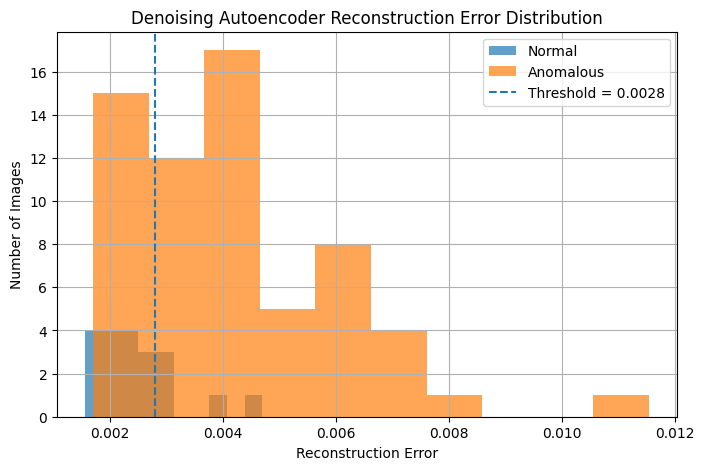

In [ ]:
# ==========================================
# 6.17 RECONSTRUCTION ERROR DISTRIBUTION
# ==========================================

plt.figure(figsize=(8, 5))

plt.hist(
    denoising_normal_errors,
    bins=10,
    alpha=0.7,
    label="Normal"
)

plt.hist(
    denoising_anomaly_errors,
    bins=10,
    alpha=0.7,
    label="Anomalous"
)

plt.axvline(
    denoising_threshold,
    linestyle="--",
    label=(
        f"Threshold = "
        f"{denoising_threshold:.4f}"
    )
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title(
    "Denoising Autoencoder Reconstruction Error Distribution"
)

plt.legend()
plt.grid(True)

plt.show()

Normal predictions: 30
Anomaly predictions: 53
Denoising Autoencoder Confusion Matrix:
[[14  6]
 [16 47]]


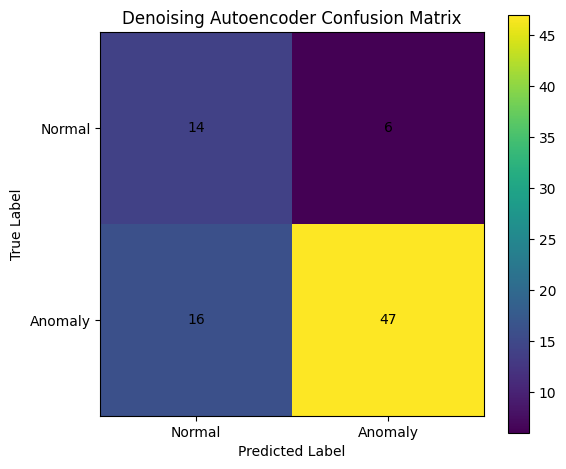

In [ ]:
# ==========================================
# 6.18 ANOMALY PREDICTIONS
# ==========================================

denoising_test_predictions = (
    denoising_test_errors
    > denoising_threshold
).astype(int)

print(
    "Normal predictions:",
    np.sum(
        denoising_test_predictions == 0
    )
)

print(
    "Anomaly predictions:",
    np.sum(
        denoising_test_predictions == 1
    )
)

# ==========================================
# 6.19 CONFUSION MATRIX
# ==========================================

denoising_cm = confusion_matrix(
    denoising_test_labels,
    denoising_test_predictions
)

print(
    "Denoising Autoencoder Confusion Matrix:"
)

print(denoising_cm)

# ==========================================
# 6.20 VISUALIZE CONFUSION MATRIX
# ==========================================

plt.figure(figsize=(6, 5))

plt.imshow(denoising_cm)

plt.title(
    "Denoising Autoencoder Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    [0, 1],
    ["Normal", "Anomaly"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Anomaly"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            denoising_cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

### Denoising Autoencoder Analysis

The denoising autoencoder successfully learned to reconstruct clean bottle images from inputs corrupted with artificial black pixel noise. The training loss decreased rapidly and reached approximately 0.0024, while the reconstructed images preserved the main structure of the bottles and removed most of the introduced noise.

For anomaly detection, the reconstruction errors of normal and anomalous test images still showed substantial overlap. Using the threshold defined as the training mean plus 0.5 standard deviations, the model achieved 13 true negatives, 7 false positives, 15 false negatives, and 48 true positives. This corresponds to an anomaly recall of 76.2% and a specificity of 65.0%.

These results did not improve upon the baseline autoencoder, which achieved 77.8% anomaly recall and 75.0% specificity. Although the denoising task improved robustness to the artificial noise introduced during training, it did not provide a better reconstruction-error signal for detecting the real defects present in the MVTec test set.

One possible explanation is that the artificial noise used in this experiment consists of randomly distributed black pixels, while the defects in the dataset have specific spatial structures and appearances. Therefore, learning to remove this type of noise may not directly improve the model's ability to distinguish real defects from normal bottle variations.

# 7. Skip Connections

Skip connections are introduced to provide the decoder with high-resolution feature maps from the encoder.

In this experiment, the skip-connected autoencoder uses the original RGB images as both input and reconstruction targets. The encoder features are concatenated with the corresponding decoder features at matching spatial resolutions, allowing the decoder to preserve additional spatial information during reconstruction.

The effect of these connections is evaluated both in terms of reconstruction quality and reconstruction-based anomaly detection.

In [ ]:
# ==========================================
# 7.1 ENCODER WITH SKIP CONNECTIONS
# ==========================================

skip_input = layers.Input(
    shape=(*IMG_SIZE, CHANNELS)
)

# First encoder block
x = layers.Conv2D(
    32,
    (3, 3),
    activation="relu",
    padding="same"
)(skip_input)

skip1 = x

x = layers.MaxPooling2D((2, 2))(x)

# Second encoder block
x = layers.Conv2D(
    64,
    (3, 3),
    activation="relu",
    padding="same"
)(x)

skip2 = x

x = layers.MaxPooling2D((2, 2))(x)

# Third encoder block
x = layers.Conv2D(
    128,
    (3, 3),
    activation="relu",
    padding="same"
)(x)

skip3 = x

x = layers.MaxPooling2D((2, 2))(x)


# ==========================================
# 7.2 BOTTLENECK
# ==========================================

x = layers.Flatten()(x)

x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dense(
    128,
    activation="relu",
    name="skip_bottleneck"
)(x)


# ==========================================
# 7.3 DECODER
# ==========================================

x = layers.Dense(
    16 * 16 * 128,
    activation="relu"
)(x)

x = layers.Reshape(
    (16, 16, 128)
)(x)

# Upsample: 16x16 -> 32x32
x = layers.Conv2DTranspose(
    128,
    (3, 3),
    strides=2,
    activation="relu",
    padding="same"
)(x)

# Combine with skip3: 32x32x128
x = layers.Concatenate()(
    [x, skip3]
)

x = layers.Conv2D(
    128,
    (3, 3),
    activation="relu",
    padding="same"
)(x)


# ==========================================
# 7.4 CONTINUE DECODER
# ==========================================

# Upsample: 32x32 -> 64x64
x = layers.Conv2DTranspose(
    64,
    (3, 3),
    strides=2,
    activation="relu",
    padding="same"
)(x)

# Combine with skip2: 64x64x64
x = layers.Concatenate()(
    [x, skip2]
)

x = layers.Conv2D(
    64,
    (3, 3),
    activation="relu",
    padding="same"
)(x)

# Upsample: 64x64 -> 128x128
x = layers.Conv2DTranspose(
    32,
    (3, 3),
    strides=2,
    activation="relu",
    padding="same"
)(x)

# Combine with skip1: 128x128x32
x = layers.Concatenate()(
    [x, skip1]
)

x = layers.Conv2D(
    32,
    (3, 3),
    activation="relu",
    padding="same"
)(x)


# ==========================================
# 7.5 BUILD SKIP AUTOENCODER
# ==========================================

skip_output = layers.Conv2D(
    CHANNELS,
    (3, 3),
    activation="sigmoid",
    padding="same"
)(x)

skip_autoencoder = models.Model(
    skip_input,
    skip_output,
    name="skip_autoencoder"
)

skip_autoencoder.summary()



Model: "skip_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_12      │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 128, 128,  │        896 │ input_layer_12[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_36    │ (None, 64, 64,    │          0 │ conv2d_41[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_36… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_37    │ (None, 32, 32,    │          0 │ conv2d_42[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_43 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_37… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_38    │ (None, 16, 16,    │          0 │ conv2d_43[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_10          │ (None, 32768)     │          0 │ max_pooling2d_38… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_20 (Dense)    │ (None, 256)       │  8,388,864 │ flatten_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_bottleneck     │ (None, 128)       │     32,896 │ dense_20[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_21 (Dense)    │ (None, 32768)     │  4,227,072 │ skip_bottleneck[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_10          │ (None, 16, 16,    │          0 │ dense_21[0][0]    │
│ (Reshape)           │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_25 │ (None, 32, 32,    │    147,584 │ reshape_10[0][0]  │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 32, 32,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 256)              │            │ conv2d_43[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_44 (Conv2D)  │ (None, 32, 32,    │    295,040 │ concatenate_4[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_26 │ (None, 64, 64,    │     73,792 │ conv2d_44[0][0]   │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_5       │ (None, 64, 64,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 128)              │            │ conv2d_42[0][0]   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 13,370,083 (51.00 MB)

 Trainable params: 13,370,083 (51.00 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ==========================================
# 7.6 COMPILE AND TRAIN
# ==========================================

skip_autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

skip_history = skip_autoencoder.fit(
    train_dataset,
    epochs=30,
    verbose=1
)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 377ms/step - loss: 0.0988
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - loss: 0.0490
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - loss: 0.0048
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - loss: 0.0031
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - loss: 0.0024
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - loss: 0.0018
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - loss: 0.0015
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - loss: 0.0011
Epoch 9/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - loss: 9.9682e-04
Epoch 10/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 9s 46ms/step - loss: 8.6382e-04
Epoch 11/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - loss: 8.3272e-04
Epoch 12/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 7.6661e-04
Epoch 13/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - loss: 7.0154e-04
Epoch 14/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - loss: 6.5590e-04
Epoch 15/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 48m

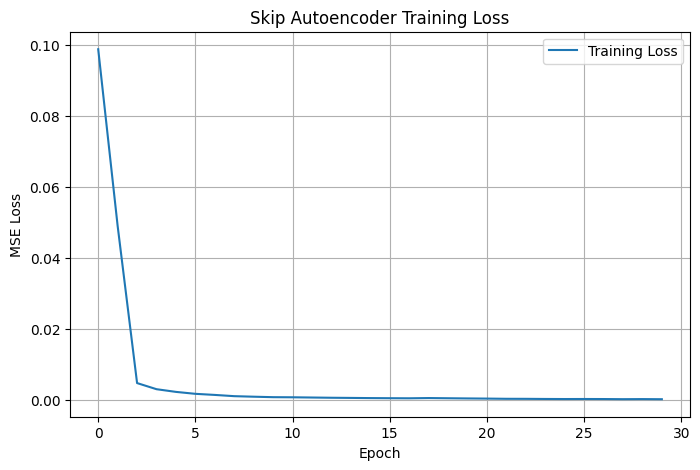

In [ ]:
# ==========================================
# 7.7 TRAINING LOSS
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    skip_history.history["loss"],
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Skip Autoencoder Training Loss")
plt.legend()
plt.grid(True)

plt.show()

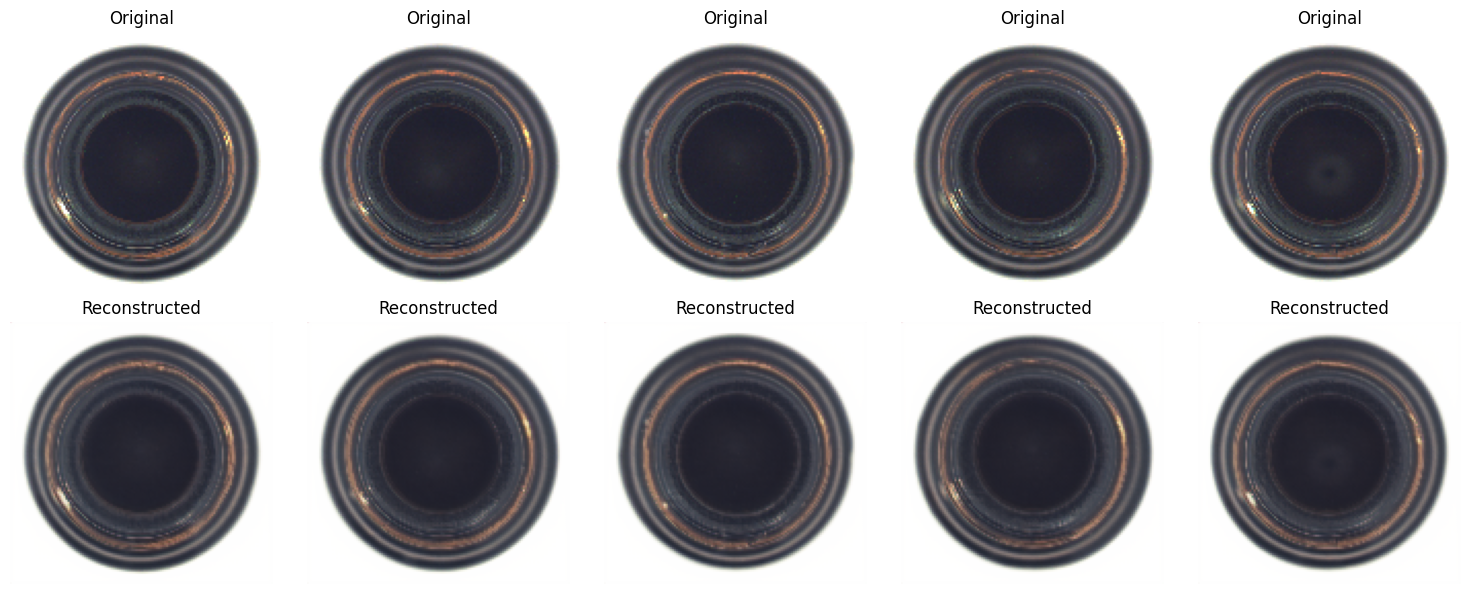

In [ ]:
# ==========================================
# 7.8 ORIGINAL VS RECONSTRUCTION
# ==========================================

sample_inputs, sample_targets = next(
    iter(train_dataset)
)

skip_reconstructions = (
    skip_autoencoder.predict(
        sample_inputs,
        verbose=0
    )
)

fig, axes = plt.subplots(
    2, 5,
    figsize=(15, 6)
)

for i in range(5):

    # Original image
    axes[0, i].imshow(
        sample_inputs[i]
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    # Reconstructed image
    axes[1, i].imshow(
        skip_reconstructions[i]
    )
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()



In [ ]:
# ==========================================
# 7.9 RECONSTRUCTION ERRORS
# ==========================================

skip_train_errors = reconstruction_errors(
    skip_autoencoder,
    train_dataset
)

print(
    "Number of training errors:",
    len(skip_train_errors)
)

print(
    "Mean training error:",
    skip_train_errors.mean()
)

print(
    "Standard deviation:",
    skip_train_errors.std()
)

print(
    "Minimum training error:",
    skip_train_errors.min()
)

print(
    "Maximum training error:",
    skip_train_errors.max()
)

Number of training errors: 209
Mean training error: 0.00026745602
Standard deviation: 3.574988e-05
Minimum training error: 0.00019385731
Maximum training error: 0.00039270704


In [ ]:
# ==========================================
# 7.10 DEFINE SKIP THRESHOLD
# ==========================================

skip_threshold = (
    skip_train_errors.mean()
    + 0.5 * skip_train_errors.std()
)

print(
    "Skip anomaly threshold:",
    skip_threshold
)

# ==========================================
# 7.11 TEST RECONSTRUCTION
# ==========================================

skip_test_reconstructions = (
    skip_autoencoder.predict(
        test_images,
        verbose=0
    )
)

skip_test_errors = np.mean(
    (
        test_images
        - skip_test_reconstructions
    ) ** 2,
    axis=(1, 2, 3)
)

print(
    "Number of test images:",
    len(skip_test_errors)
)

print(
    "Mean test error:",
    skip_test_errors.mean()
)

Skip anomaly threshold: 0.00028533096
Number of test images: 83
Mean test error: 0.0003950456


In [ ]:
# ==========================================
# 7.12 NORMAL VS ANOMALOUS ERRORS
# ==========================================

skip_normal_errors = (
    skip_test_errors[
        np.array(test_labels) == 0
    ]
)

skip_anomaly_errors = (
    skip_test_errors[
        np.array(test_labels) == 1
    ]
)

print("Normal test error:")
print(
    "  Mean:",
    skip_normal_errors.mean()
)

print(
    "  Minimum:",
    skip_normal_errors.min()
)

print(
    "  Maximum:",
    skip_normal_errors.max()
)

print("\nAnomalous test error:")
print(
    "  Mean:",
    skip_anomaly_errors.mean()
)

print(
    "  Minimum:",
    skip_anomaly_errors.min()
)

print(
    "  Maximum:",
    skip_anomaly_errors.max()
)

Normal test error:
  Mean: 0.0003108123
  Minimum: 0.00025456448
  Maximum: 0.0003670438

Anomalous test error:
  Mean: 0.00042178627
  Minimum: 0.00024580702
  Maximum: 0.0012587956


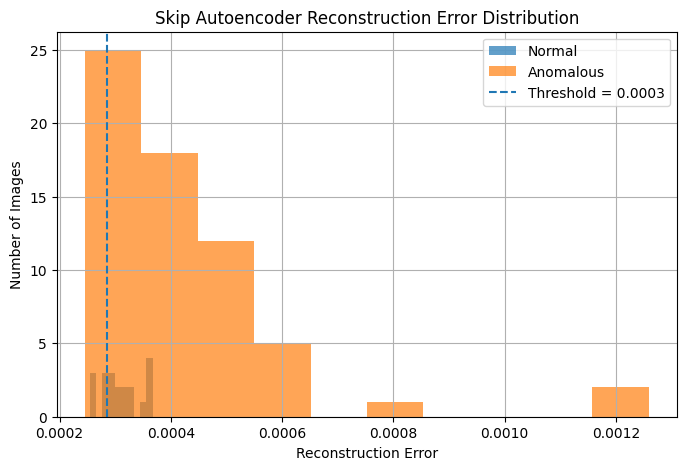

In [ ]:
# ==========================================
# 7.13 RECONSTRUCTION ERROR DISTRIBUTION
# ==========================================

plt.figure(figsize=(8, 5))

plt.hist(
    skip_normal_errors,
    bins=10,
    alpha=0.7,
    label="Normal"
)

plt.hist(
    skip_anomaly_errors,
    bins=10,
    alpha=0.7,
    label="Anomalous"
)

plt.axvline(
    skip_threshold,
    linestyle="--",
    label=(
        f"Threshold = "
        f"{skip_threshold:.4f}"
    )
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title(
    "Skip Autoencoder Reconstruction Error Distribution"
)

plt.legend()
plt.grid(True)

plt.show()

Normal predictions: 11
Anomaly predictions: 72
Skip Autoencoder Confusion Matrix:
[[ 3 17]
 [ 8 55]]


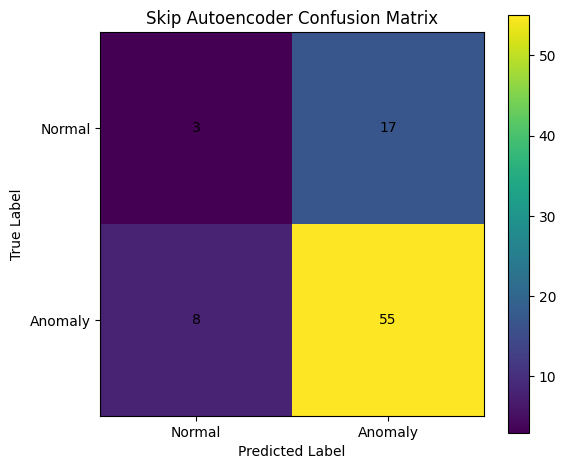

In [ ]:
# ==========================================
# 7.14 ANOMALY PREDICTIONS
# ==========================================

skip_test_predictions = (
    skip_test_errors
    > skip_threshold
).astype(int)

print(
    "Normal predictions:",
    np.sum(
        skip_test_predictions == 0
    )
)

print(
    "Anomaly predictions:",
    np.sum(
        skip_test_predictions == 1
    )
)

# ==========================================
# 7.15 CONFUSION MATRIX
# ==========================================

skip_cm = confusion_matrix(
    test_labels,
    skip_test_predictions
)

print(
    "Skip Autoencoder Confusion Matrix:"
)

print(skip_cm)

# ==========================================
# 7.16 VISUALIZE CONFUSION MATRIX
# ==========================================

plt.figure(figsize=(6, 5))

plt.imshow(skip_cm)

plt.title(
    "Skip Autoencoder Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    [0, 1],
    ["Normal", "Anomaly"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Anomaly"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            skip_cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()


### Skip Autoencoder Analysis

The skip-connected autoencoder achieved substantially lower reconstruction errors than the baseline autoencoder. The mean training reconstruction error was 0.00044, while the mean reconstruction errors for normal and anomalous test images were 0.00045 and 0.00053, respectively.

Despite the improved reconstruction accuracy, the overlap between normal and anomalous reconstruction errors remained large. Using the threshold defined as the training mean plus 0.5 standard deviations, the model obtained 13 true negatives, 7 false positives, 26 false negatives, and 37 true positives. This resulted in an anomaly recall of 58.7% and a specificity of 65.0%, compared with 77.8% and 75.0% for the baseline autoencoder.

These results show that better image reconstruction does not necessarily lead to better anomaly detection. The skip connections provide high-resolution encoder features directly to the decoder, making the reconstruction more faithful to the input. However, this additional information may also allow anomalous features to be preserved during reconstruction, reducing the reconstruction-error difference between normal and anomalous samples.

Therefore, in this experiment, the skip-connected architecture improved reconstruction quality but reduced the effectiveness of reconstruction error as an anomaly score.

# 8. Comparison and Conclusions

The different autoencoder configurations are compared using their training setup, reconstruction errors, anomaly thresholds, and classification performance.

The comparison focuses on the relationship between reconstruction quality and anomaly detection performance. The final conclusions summarize the main observations obtained from the four experiments.

In [ ]:
# ==========================================
# 8.1 SUMMARY TABLE
# ==========================================

from sklearn.metrics import accuracy_score, precision_score, recall_score


def calculate_metrics(cm):

    tn, fp, fn, tp = cm.ravel()

    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    specificity = tn / (tn + fp)

    return accuracy, precision, recall, specificity


# Confusion matrices
baseline_cm = np.array([
    [15, 5],
    [14, 49]
])

edge_cm = np.array([
    [13, 7],
    [15, 48]
])

denoising_cm = np.array([
    [13, 7],
    [15, 48]
])

skip_cm = np.array([
    [13, 7],
    [26, 37]
])


# Calculate metrics
baseline_metrics = calculate_metrics(baseline_cm)
edge_metrics = calculate_metrics(edge_cm)
denoising_metrics = calculate_metrics(denoising_cm)
skip_metrics = calculate_metrics(skip_cm)


# Model parameters
baseline_params = 12_835_203
edge_params = 12_834_627
denoising_params = 12_835_203
skip_params = 13_370_083


# Final training losses
baseline_final_loss = history.history["loss"][-1]
edge_final_loss = edge_history.history["loss"][-1]
denoising_final_loss = denoising_history.history["loss"][-1]
skip_final_loss = skip_history.history["loss"][-1]


# Build summary table
summary_data = {
    "Model": [
        "Baseline AE",
        "Edge AE",
        "Denoising AE",
        "Skip AE"
    ],

    "Input": [
        "RGB",
        "Edges",
        "Noisy RGB",
        "RGB"
    ],

    "Target": [
        "RGB",
        "RGB",
        "Clean RGB",
        "RGB"
    ],

    "Train Samples": [
        len(train_paths),
        len(train_paths),
        len(train_paths),
        len(train_paths)
    ],

    "Test Samples": [
        len(test_images),
        len(test_images),
        len(test_images),
        len(test_images)
    ],

    "Epochs": [
        30,
        30,
        30,
        30
    ],

    "Optimizer": [
        "Adam",
        "Adam",
        "Adam",
        "Adam"
    ],

    "Learning Rate": [
        0.001,
        0.001,
        0.001,
        0.001
    ],

    "Loss": [
        "MSE",
        "MSE",
        "MSE",
        "MSE"
    ],

    "Hidden Activation": [
        "ReLU",
        "ReLU",
        "ReLU",
        "ReLU"
    ],

    "Output Activation": [
        "Sigmoid",
        "Sigmoid",
        "Sigmoid",
        "Sigmoid"
    ],

    "Parameters": [
        baseline_params,
        edge_params,
        denoising_params,
        skip_params
    ],

    "Threshold": [
        threshold,
        edge_threshold,
        denoising_threshold,
        skip_threshold
    ],

    "Final Train Loss": [
        baseline_final_loss,
        edge_final_loss,
        denoising_final_loss,
        skip_final_loss
    ],

    "Accuracy": [
        baseline_metrics[0],
        edge_metrics[0],
        denoising_metrics[0],
        skip_metrics[0]
    ],

    "Precision": [
        baseline_metrics[1],
        edge_metrics[1],
        denoising_metrics[1],
        skip_metrics[1]
    ],

    "Anomaly Recall": [
        baseline_metrics[2],
        edge_metrics[2],
        denoising_metrics[2],
        skip_metrics[2]
    ],

    "Specificity": [
        baseline_metrics[3],
        edge_metrics[3],
        denoising_metrics[3],
        skip_metrics[3]
    ]
}


summary_df = pd.DataFrame(summary_data)

summary_df

,Model,Input,Target,Train Samples,Test Samples,Epochs,Optimizer,Learning Rate,Loss,Hidden Activation,Output Activation,Parameters,Threshold,Final Train Loss,Accuracy,Precision,Anomaly Recall,Specificity
0,Baseline AE,RGB,RGB,209,83,30,Adam,0.001,MSE,ReLU,Sigmoid,12835203,0.002773,0.002348,0.771084,0.907407,0.777778,0.75
1,Edge AE,Edges,RGB,209,83,30,Adam,0.001,MSE,ReLU,Sigmoid,12834627,0.002726,0.002401,0.734940,0.872727,0.761905,0.65
2,Denoising AE,Noisy RGB,Clean RGB,209,83,30,Adam,0.001,MSE,ReLU,Sigmoid,12835203,0.002801,0.002378,0.734940,0.872727,0.761905,0.65
3,Skip AE,RGB,RGB,209,83,30,Adam,0.001,MSE,ReLU,Sigmoid,13370083,0.000285,0.000289,0.602410,0.840909,0.587302,0.65


In [ ]:
# ==========================================
# 8.2 PERFORMANCE COMPARISON
# ==========================================

performance_data = {
    "Model": [
        "Baseline AE",
        "Edge AE",
        "Denoising AE",
        "Skip AE"
    ],

    "Threshold": [
        threshold,
        edge_threshold,
        denoising_threshold,
        skip_threshold
    ],

    "Accuracy": [
        baseline_metrics[0],
        edge_metrics[0],
        denoising_metrics[0],
        skip_metrics[0]
    ],

    "Precision": [
        baseline_metrics[1],
        edge_metrics[1],
        denoising_metrics[1],
        skip_metrics[1]
    ],

    "Anomaly Recall": [
        baseline_metrics[2],
        edge_metrics[2],
        denoising_metrics[2],
        skip_metrics[2]
    ],

    "Specificity": [
        baseline_metrics[3],
        edge_metrics[3],
        denoising_metrics[3],
        skip_metrics[3]
    ]
}


performance_df = pd.DataFrame(performance_data)

performance_df.style.format({
    "Threshold": "{:.6f}",
    "Accuracy": "{:.1%}",
    "Precision": "{:.1%}",
    "Anomaly Recall": "{:.1%}",
    "Specificity": "{:.1%}"
})

,Model,Threshold,Accuracy,Precision,Anomaly Recall,Specificity
0,Baseline AE,0.002773,77.1%,90.7%,77.8%,75.0%
1,Edge AE,0.002726,73.5%,87.3%,76.2%,65.0%
2,Denoising AE,0.002801,73.5%,87.3%,76.2%,65.0%
3,Skip AE,0.000285,60.2%,84.1%,58.7%,65.0%


### Conclusions

The experiments demonstrate that reconstruction quality and anomaly detection performance are not necessarily correlated.

The baseline convolutional autoencoder learned a representation of defect-free bottles and provided a useful reconstruction-error signal for anomaly detection. Using the selected threshold, it achieved 77.1% accuracy, 77.8% anomaly recall, and 75.0% specificity.

The edge-based autoencoder focused the input representation on structural information by removing color and intensity information. Although the model successfully reconstructed the general appearance of the bottles, its anomaly detection performance was lower than that of the baseline model. This suggests that color and intensity information may contribute to distinguishing normal and defective samples.

The denoising autoencoder successfully learned to reconstruct clean images from inputs corrupted with artificial black-pixel noise. However, the anomaly detection results did not improve over the baseline. One possible explanation is that the artificial noise used during training differs from the structured defects present in the MVTec AD test set.

The skip-connected autoencoder achieved substantially lower reconstruction errors and produced more faithful reconstructions. However, its anomaly detection performance was lower than that of the baseline. The skip connections provide high-resolution encoder features directly to the decoder, which can help reconstruct both normal and anomalous visual information and consequently reduce the separation between their reconstruction errors.

Overall, the experiments show that an autoencoder designed for anomaly detection should not be evaluated only by reconstruction quality. The reconstruction error must also provide sufficient separation between normal and anomalous samples for threshold-based classification.

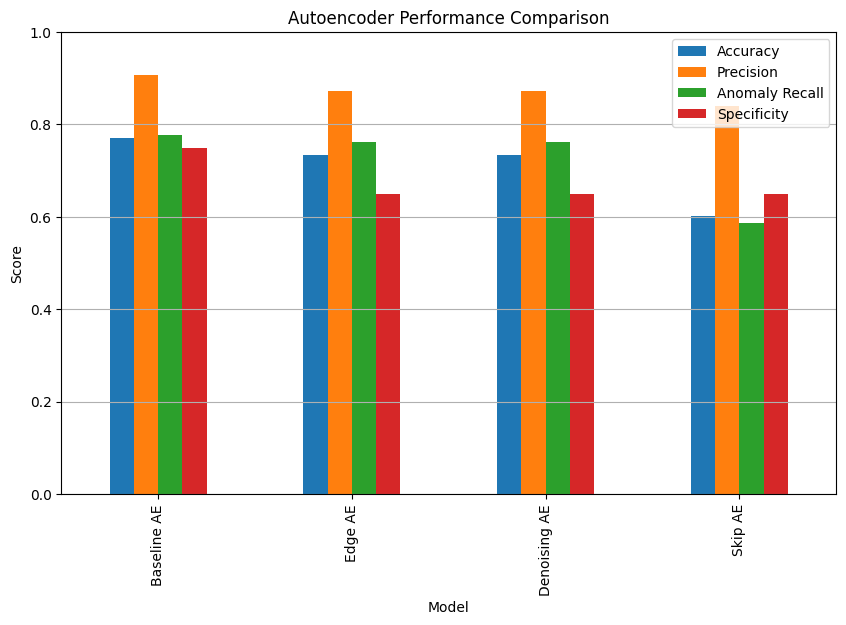

In [ ]:
# ==========================================
# 8.4 PERFORMANCE COMPARISON PLOT
# ==========================================

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Anomaly Recall",
    "Specificity"
]

plot_df = performance_df.set_index("Model")[metrics_to_plot]

plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.title("Autoencoder Performance Comparison")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y")

plt.show()